In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
from src.ingestion import load_tml_seasons, to_player_match_long
from src.metrics import season_profile, bootstrap_season_diff

# 1. Cargar y guardar versión procesada para los Bloques 2, 3 y 4
matches = load_tml_seasons("../data/raw", years=range(2021, 2027))
long_df = to_player_match_long(matches)
long_df.to_parquet("../data/processed/atp_long_2021_2026.parquet", index=False)

# 2. Evolución completa de Zverev (2021-2026)
zverev_yearly = season_profile(long_df, "Alexander Zverev")
display(zverev_yearly.round(2))

# 3. Test de hipótesis: ¿2026 supera a su último pico (2024) o solo rebota tras 2025?
# ¿Es una mejora real o podría deberse al azar de los partidos jugados?
key_metrics = [
    "tpw_pct", "dominance_ratio", "first_in_pct", "first_won_pct",
    "second_won_pct", "hold_pct", "ret_won_pct", "break_pct"
]
diff_24_26 = bootstrap_season_diff(long_df, "Alexander Zverev", 2024, 2026, key_metrics)
diff_25_26 = bootstrap_season_diff(long_df, "Alexander Zverev", 2025, 2026, key_metrics)

display(diff_24_26)
display(diff_25_26)

,season,matches,win_pct,tpw_pct,dominance_ratio,first_in_pct,first_won_pct,second_won_pct,sv_won_pct,ret_won_pct,hold_pct,break_pct,hold_plus_break,bp_saved_pct,bp_conv_pct,ace_pct,df_pct
0,2021,67.0,77.61,53.41,1.27,67.47,77.35,51.55,68.96,39.39,86.07,27.47,113.54,60.19,41.65,13.36,5.13
1,2022,37.0,72.97,52.54,1.16,71.97,72.89,48.22,65.98,39.49,83.52,26.61,110.12,60.73,45.80,9.66,4.99
2,2023,80.0,67.50,51.73,1.13,70.56,73.86,49.21,66.60,37.61,84.42,22.90,107.32,63.03,36.42,10.21,3.73
3,2024,88.0,77.27,53.41,1.28,71.17,76.73,54.72,70.39,37.86,90.03,22.42,112.44,69.11,37.11,11.62,2.65
4,2025,80.0,68.75,52.23,1.18,72.10,73.79,53.56,68.15,37.51,86.53,22.05,108.58,62.64,39.81,9.79,2.58
5,2026,86.0,77.91,53.20,1.28,72.07,76.91,56.81,71.30,36.66,90.33,21.58,111.91,63.23,40.38,12.64,2.81


,metric,val_2024,val_2026,diff,ci_95_low,ci_95_high,p_value,significant_95
0,tpw_pct,53.41,53.20,-0.21,-1.50,1.05,0.7444,False
1,dominance_ratio,1.28,1.28,-0.00,-0.12,0.11,0.9764,False
2,first_in_pct,71.17,72.07,0.90,-0.87,2.61,0.3116,False
3,first_won_pct,76.73,76.91,0.18,-1.98,2.30,0.8968,False
4,second_won_pct,54.72,56.81,2.09,-1.14,5.22,0.2008,False
5,hold_pct,90.03,90.33,0.31,-2.70,3.10,0.8540,False
6,ret_won_pct,37.86,36.66,-1.20,-3.35,0.87,0.2580,False
7,break_pct,22.42,21.58,-0.84,-5.16,3.40,0.7084,False


,metric,val_2025,val_2026,diff,ci_95_low,ci_95_high,p_value,significant_95
0,tpw_pct,52.23,53.20,0.97,-0.45,2.34,0.1888,False
1,dominance_ratio,1.18,1.28,0.10,-0.02,0.21,0.0968,False
2,first_in_pct,72.10,72.07,-0.03,-1.82,1.73,0.9624,False
3,first_won_pct,73.79,76.91,3.12,0.88,5.32,0.0056,True
4,second_won_pct,53.56,56.81,3.25,0.17,6.43,0.0392,True
5,hold_pct,86.53,90.33,3.80,0.64,6.92,0.0184,True
6,ret_won_pct,37.51,36.66,-0.85,-3.29,1.47,0.4720,False
7,break_pct,22.05,21.58,-0.47,-5.24,4.10,0.8176,False


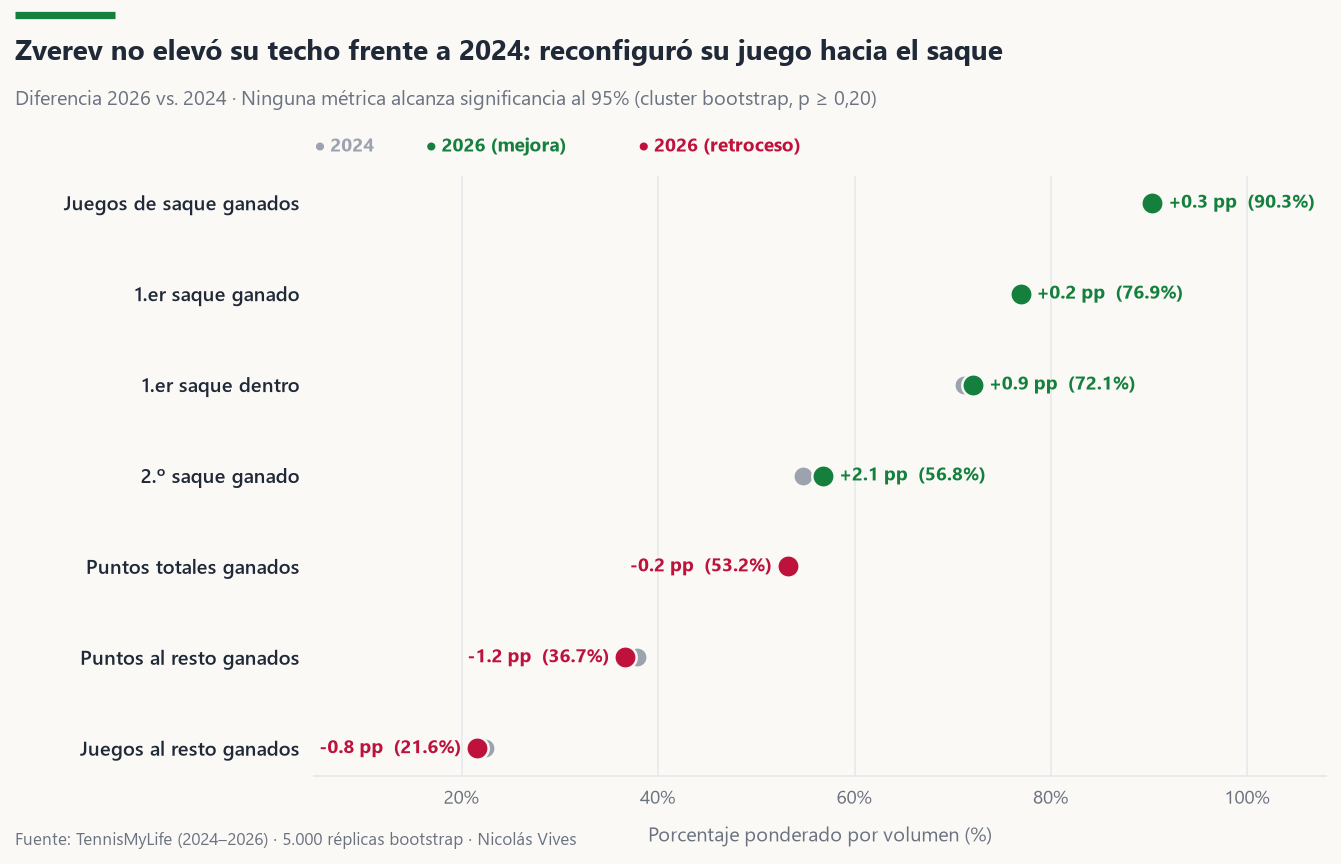

In [3]:
from src.viz import PALETTE, apply_editorial_style, add_editorial_chrome, save_figure

apply_editorial_style()

plot_metrics = [
    ("hold_pct", "Juegos de saque ganados"),
    ("first_won_pct", "1.er saque ganado"),
    ("first_in_pct", "1.er saque dentro"),
    ("second_won_pct", "2.º saque ganado"),
    ("tpw_pct", "Puntos totales ganados"),
    ("ret_won_pct", "Puntos al resto ganados"),
    ("break_pct", "Juegos al resto ganados"),
]

df_plot = diff_24_26.set_index("metric").loc[[m[0] for m in plot_metrics]].copy()
df_plot["label"] = [m[1] for m in plot_metrics]

fig, ax = plt.subplots(figsize=(9.5, 5.9))
ax.spines["left"].set_visible(False)
ax.grid(axis="y", visible=False)

for y, (_, row) in enumerate(df_plot.iterrows()):
    v24, v26, diff = row["val_2024"], row["val_2026"], row["diff"]
    color = PALETTE["zverev"] if diff >= 0 else PALETTE["negative"]

    # Segmento conector y puntos
    ax.plot([v24, v26], [y, y], color=color, lw=3.0, alpha=0.85, zorder=2)
    ax.scatter(v24, y, color=PALETTE["neutral"], s=95, edgecolors=PALETTE["bg"], lw=1.2, zorder=3)
    ax.scatter(v26, y, color=color, s=115, edgecolors=PALETTE["bg"], lw=1.2, zorder=4)

    # Etiqueta siempre fuera del extremo para evitar solapes con el punto de 2024
    sign = "+" if diff >= 0 else ""
    if diff >= 0:
        x_txt, ha = max(v24, v26) + 1.6, "left"
    else:
        x_txt, ha = min(v24, v26) - 1.6, "right"

    ax.text(
        x_txt, y, f"{sign}{diff:.1f} pp  ({v26:.1f}%)",
        va="center", ha=ha, fontsize=9.2, fontweight="bold", color=color,
    )

# Clave visual en línea (sustituye a la leyenda clásica)
ax.text(0.00, 1.04, "● 2024", transform=ax.transAxes, color=PALETTE["neutral"], fontsize=9.2, fontweight="bold")
ax.text(0.11, 1.04, "● 2026 (mejora)", transform=ax.transAxes, color=PALETTE["zverev"], fontsize=9.2, fontweight="bold")
ax.text(0.32, 1.04, "● 2026 (retroceso)", transform=ax.transAxes, color=PALETTE["negative"], fontsize=9.2, fontweight="bold")

ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels(df_plot["label"], color=PALETTE["text"], fontweight="medium")
ax.invert_yaxis()
ax.set_xlim(5, 108)
ax.set_xlabel("Porcentaje ponderado por volumen (%)")
ax.xaxis.set_major_formatter(lambda x, _: f"{int(x)}%")

add_editorial_chrome(
    fig,
    title="Zverev no elevó su techo frente a 2024: reconfiguró su juego hacia el saque",
    subtitle="Diferencia 2026 vs. 2024 · Ninguna métrica alcanza significancia al 95% (cluster bootstrap, p ≥ 0,20)",
    source="Fuente: TennisMyLife (2024–2026) · 5.000 réplicas bootstrap · Nicolás Vives",
    left=0.25,
    right=0.96,
    top_pad_in=1.25,
)

save_figure(fig, "01_zverev_dumbbell_2024_2026")
plt.show()